# Challenge 1: datos y análisis exploratorio

Tu primera responsabilidad es preparar una fuente de datos confiable para el proyecto de clasificación de vinos.

**Entrada:** `data/raw/wine.csv`  
**Salidas:** `data/processed/train.csv`, `data/processed/test.csv` y `artifacts/data_contract.json`

> El conjunto de test se crea aquí, pero no debe explorarse ni utilizarse después del split.

## Objetivos

- cargar y validar datos externos;
- identificar problemas básicos de calidad;
- crear un split reproducible y estratificado;
- realizar EDA únicamente sobre entrenamiento;
- guardar datos y metadatos para la siguiente etapa.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split

np.random.seed(42)
plt.rcParams["figure.figsize"] = (7, 4)

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga y profiling

In [3]:
DATA_PATH = RAW_DATA_DIR / "wine.csv"
# En la carpeta entregada el CSV está en data/wine.csv (sin subcarpeta raw)
if not DATA_PATH.exists():
    DATA_PATH = PROJECT_DIR / "data" / "wine.csv"

df = pd.read_csv(DATA_PATH)
print("Archivo cargado:", DATA_PATH.relative_to(PROJECT_DIR))
df.head()

Archivo cargado: data\wine.csv


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [4]:
TARGET = "target"
feature_names = df.drop(columns=TARGET).columns.tolist()

print(f"Filas: {df.shape[0]}")
print(f"Columnas predictoras: {len(feature_names)}")
print("Valores faltantes:", int(df.isna().sum().sum()))
print("Filas duplicadas:", int(df.duplicated().sum()))
print("Valores de target:", sorted(df[TARGET].unique()))

print("\nDistribución de la clase:")
display(pd.DataFrame({
    "conteo": df[TARGET].value_counts().sort_index(),
    "proporción": df[TARGET].value_counts(normalize=True).sort_index().round(3),
}))

profile = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "unique": df.nunique(),
    "min": df.min(),
    "max": df.max(),
    "mean": df.mean().round(2),
})
profile

Filas: 178
Columnas predictoras: 13
Valores faltantes: 0
Filas duplicadas: 0
Valores de target: [np.int64(0), np.int64(1), np.int64(2)]

Distribución de la clase:


,conteo,proporción
target,,
0,59,0.331
1,71,0.399
2,48,0.270


,dtype,missing,unique,min,max,mean
alcohol,float64,0,126,11.03,14.83,13.00
malic_acid,float64,0,133,0.74,5.80,2.34
ash,float64,0,79,1.36,3.23,2.37
alcalinity_of_ash,float64,0,63,10.60,30.00,19.49
magnesium,float64,0,53,70.00,162.00,99.74
total_phenols,float64,0,97,0.98,3.88,2.30
flavanoids,float64,0,132,0.34,5.08,2.03
nonflavanoid_phenols,float64,0,39,0.13,0.66,0.36
proanthocyanins,float64,0,101,0.41,3.58,1.59
color_intensity,float64,0,132,1.28,13.00,5.06


**Conclusión de calidad:**

> El dataset tiene 178 filas, 13 variables predictoras numéricas (`float64`) y la columna `target` con tres clases (0, 1, 2). No hay valores faltantes ni filas duplicadas, y todos los rangos son físicamente razonables, así que no fue necesario eliminar ni corregir registros. Las clases están algo desbalanceadas (33 % / 40 % / 27 %), por lo que el split se hace **estratificado**. Aunque hoy no hay nulos, en el siguiente challenge se incluye un imputador por mediana dentro del pipeline para que el modelo tolere datos nuevos incompletos.

## 2. Split train/test

In [5]:
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df["target"],
    random_state=RANDOM_STATE,
)

print("Proporción de clases en train:", train_df["target"].value_counts(normalize=True).sort_index().round(3).tolist())
print("Proporción de clases en test: ", test_df["target"].value_counts(normalize=True).sort_index().round(3).tolist())

Proporción de clases en train: [0.331, 0.401, 0.268]
Proporción de clases en test:  [0.333, 0.389, 0.278]


In [6]:
# Verificación del split
assert len(train_df) + len(test_df) == len(df)
assert set(train_df.index).isdisjoint(set(test_df.index))
print("Train:", train_df.shape)
print("Test:", test_df.shape)

Train: (142, 14)
Test: (36, 14)


## 3. EDA sobre entrenamiento

Incluye:

- distribución de clases;
- distribuciones o boxplots de variables relevantes;
- correlaciones;
- tres hallazgos que puedan influir en el modelado.

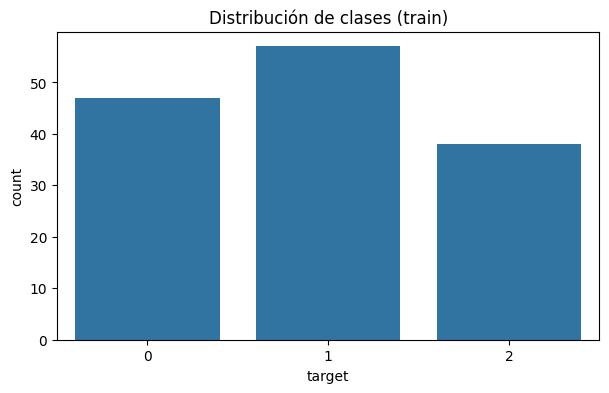

,mean,std,min,max
alcohol,12.97,0.80,11.03,14.83
malic_acid,2.34,1.10,0.74,5.80
ash,2.36,0.27,1.36,3.22
alcalinity_of_ash,19.63,3.38,10.60,30.00
magnesium,99.63,14.94,70.00,162.00
total_phenols,2.27,0.62,0.98,3.88
flavanoids,1.99,0.95,0.34,3.74
nonflavanoid_phenols,0.36,0.12,0.13,0.63
proanthocyanins,1.60,0.58,0.42,3.58
color_intensity,4.99,2.33,1.28,13.00


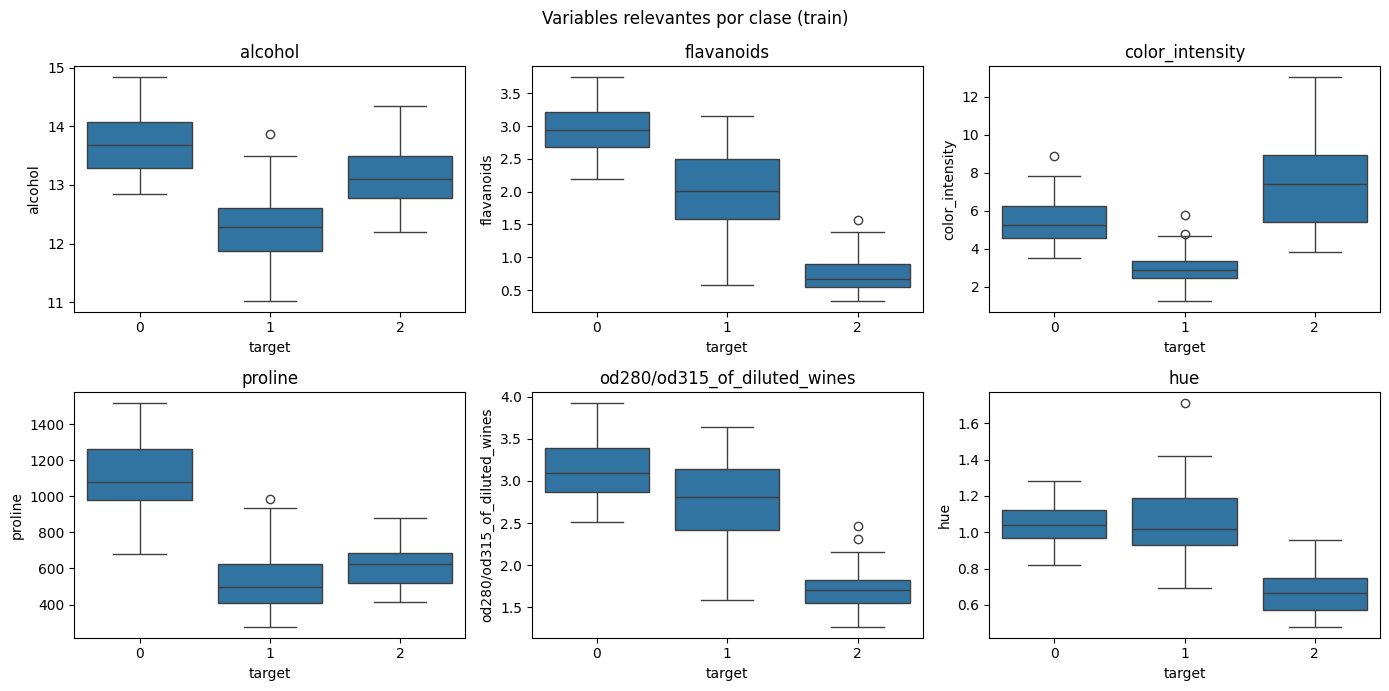

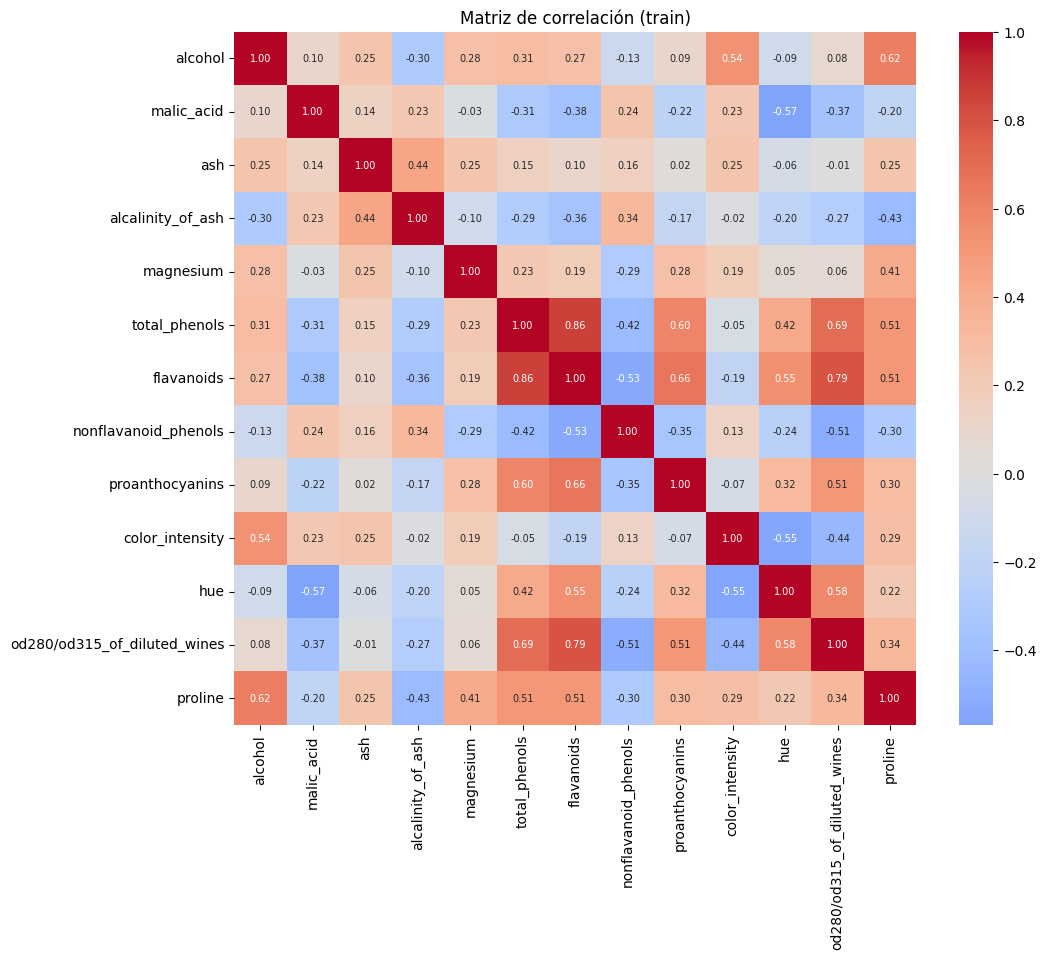

Pares de variables más correlacionados:


,level_0,level_1,corr
71,total_phenols,flavanoids,0.86
89,flavanoids,od280/od315_of_diluted_wines,0.79
76,total_phenols,od280/od315_of_diluted_wines,0.69
86,flavanoids,proanthocyanins,0.66
12,alcohol,proline,0.62


In [7]:
# A partir de aquí solo se usa train_df
features = [c for c in train_df.columns if c != "target"]

# 1. Distribución de clases
ax = sns.countplot(data=train_df, x="target")
ax.set_title("Distribución de clases (train)")
plt.show()

# 2. Escala de las variables
display(train_df[features].describe().T[["mean", "std", "min", "max"]].round(2))

# 3. Boxplots por clase de las variables más informativas
key_features = ["alcohol", "flavanoids", "color_intensity",
                "proline", "od280/od315_of_diluted_wines", "hue"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), key_features):
    sns.boxplot(data=train_df, x="target", y=col, ax=ax)
    ax.set_title(col)
plt.suptitle("Variables relevantes por clase (train)")
plt.tight_layout()
plt.show()

# 4. Correlaciones entre variables
corr = train_df[features].corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Matriz de correlación (train)")
plt.show()

pairs = (
    corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
    .stack()
    .rename("corr")
    .reset_index()
)
pairs["abs"] = pairs["corr"].abs()
print("Pares de variables más correlacionados:")
display(pairs.sort_values("abs", ascending=False).head(5).drop(columns="abs").round(2))

**Hallazgos:**

1. **Escalas muy distintas:** `proline` llega a ~1500 y `magnesium` a ~160, mientras que `hue` o `nonflavanoid_phenols` están por debajo de 2. Los modelos basados en distancias (KNN) o en coeficientes regularizados (regresión logística) necesitan `StandardScaler`; los árboles no.
2. **Variables muy discriminantes:** `flavanoids` separa casi por completo la clase 2 (media 0.78 frente a 2.93 y 2.01). `proline` distingue la clase 0 (media ~1092 frente a ~526 y ~623). `color_intensity` es baja en la clase 1 (~3.0 frente a 5.5 y 7.4). Pocas variables ya separan bien las clases, así que se puede esperar un accuracy alto incluso con modelos simples.
3. **Multicolinealidad:** `total_phenols`–`flavanoids` (r = 0.86), `flavanoids`–`od280/od315` (0.79) y `total_phenols`–`od280/od315` (0.69) están muy correlacionadas. Aportan información redundante: los coeficientes de la regresión logística serán menos interpretables uno a uno, y la regularización (`C`) ayuda a controlarlo.

## 4. Persistencia de datos y contrato

In [8]:
train_out = train_df.reset_index(drop=True)
test_out = test_df.reset_index(drop=True)
train_out.to_csv(PROCESSED_DATA_DIR / "train.csv", index=False)
test_out.to_csv(PROCESSED_DATA_DIR / "test.csv", index=False)

contract = {
    "dataset": "Wine (UCI)",
    "target": "target",
    "target_names": ["class_0", "class_1", "class_2"],
    "features": features,
    "random_state": RANDOM_STATE,
    "test_size": 0.20,
    "n_train": len(train_out),
    "n_test": len(test_out),
    "sklearn_version": sklearn.__version__,
}
(ARTIFACTS_DIR / "data_contract.json").write_text(
    json.dumps(contract, indent=2), encoding="utf-8"
)
print("Datos y contrato guardados.")

Datos y contrato guardados.


In [9]:
# Verificación de entrega
assert (PROCESSED_DATA_DIR / "train.csv").exists()
assert (PROCESSED_DATA_DIR / "test.csv").exists()
assert (ARTIFACTS_DIR / "data_contract.json").exists()
print("Challenge 1 completado.")

Challenge 1 completado.


## Checklist

- [x] Cargué el CSV desde `data/raw` (con respaldo a `data/wine.csv`, que es donde viene el archivo).
- [x] Revisé calidad y distribución de la clase.
- [x] Realicé un split estratificado.
- [x] No exploré el conjunto de test.
- [x] Guardé los tres artefactos requeridos.